# Introduction to Diffusers with the Kaggle Smithsonian Butterfly Dataset

This notebook trains an unconditional diffusion model locally with Hugging Face's **Diffusers library**, but it does **not** download a dataset or pretrained model from the Hugging Face Hub and does not upload anything.

Training images come from the Kaggle dataset [`thedevastator/smithsonian-butterfly-dataset`](https://www.kaggle.com/datasets/thedevastator/smithsonian-butterfly-dataset).

## What You Will Learn

- Download a public dataset with KaggleHub.
- Decode the dataset's images embedded inside `train.csv`.
- Train a small `UNet2DModel` locally with a DDPM noise scheduler.
- Generate butterfly images with a locally constructed `DDPMPipeline` and save them as timestamped grids.
- Optionally save the trained pipeline to disk.

No Hugging Face account, token, model download, or model upload is required.

## Step 1: Install project dependencies

Dependencies are managed by the repository-level `requirements.txt`. `%pip` installs them into the active notebook kernel.

In [10]:
%pip install -r ../../requirements.txt

Note: you may need to restart the kernel to use updated packages.


## Step 2: Imports and device selection

In [11]:
import ast
import csv
import sys
from datetime import datetime
from io import BytesIO
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
import truststore
from diffusers import DDPMPipeline, DDPMScheduler, UNet2DModel
from PIL import Image
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# Use the operating system trust store so corporate TLS certificates are honored.
truststore.inject_into_ssl()

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"PyTorch: {torch.__version__}")
print(f"Using device: {device}")


PyTorch: 2.15.0
Using device: mps


## Step 3: Download the Kaggle dataset

KaggleHub caches the 312 MB archive under `~/.cache/kagglehub`, so subsequent runs reuse it. This public dataset does not normally require Kaggle credentials.

In [12]:
KAGGLE_DATASET = "thedevastator/smithsonian-butterfly-dataset"

dataset_root = Path(kagglehub.dataset_download(KAGGLE_DATASET))
csv_path = dataset_root / "train.csv"
if not csv_path.is_file():
    raise FileNotFoundError(f"Expected train.csv inside Kaggle dataset directory: {dataset_root}")

print(f"Dataset directory: {dataset_root}")
print(f"CSV size: {csv_path.stat().st_size / (1024 ** 2):.1f} MB")

Dataset directory: /Users/Z002YK9/.cache/kagglehub/datasets/thedevastator/smithsonian-butterfly-dataset/versions/2
CSV size: 654.6 MB


## Step 4: Extract the embedded images

This Kaggle dataset stores each image as a Python bytes literal in the CSV's `image` column. The cell below safely decodes those bytes with `ast.literal_eval` and writes PNG files to the Kaggle cache. Existing files are reused after an interrupted or completed extraction.

In [13]:
images_dir = dataset_root / "extracted_images"
images_dir.mkdir(exist_ok=True)

csv.field_size_limit(sys.maxsize)
extracted_count = 0

with csv_path.open(newline="", encoding="utf-8") as csv_file:
    reader = csv.DictReader(csv_file)
    if "image" not in (reader.fieldnames or []):
        raise ValueError("The Kaggle CSV does not contain the expected 'image' column.")

    for index, row in enumerate(reader):
        output_path = images_dir / f"butterfly_{index:04d}.png"
        if not output_path.exists():
            payload = ast.literal_eval(row["image"])
            image_bytes = payload.get("bytes") if isinstance(payload, dict) else None
            if not isinstance(image_bytes, bytes):
                raise ValueError(f"Row {index} does not contain valid embedded image bytes.")
            with Image.open(BytesIO(image_bytes)) as image:
                image.convert("RGB").save(output_path)
        extracted_count += 1

image_files = sorted(images_dir.glob("*.png"))
if len(image_files) != extracted_count:
    raise RuntimeError(
        f"Expected {extracted_count} extracted images, found {len(image_files)} in {images_dir}."
    )

print(f"Ready to train with {len(image_files)} images from: {images_dir}")

Ready to train with 1000 images from: /Users/Z002YK9/.cache/kagglehub/datasets/thedevastator/smithsonian-butterfly-dataset/versions/2/extracted_images


## Step 5: Create the PyTorch dataset and DataLoader

Batch shape: (8, 3, 128, 128)


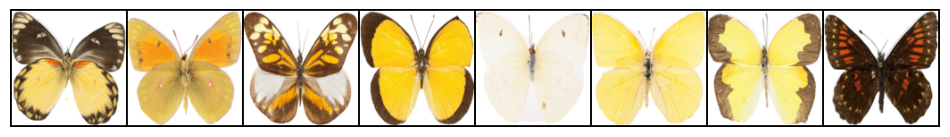

In [14]:
IMAGE_SIZE = 128
BATCH_SIZE = 8 if device.type == "mps" else 32

preprocess = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.5] * 3, [0.5] * 3),
    ]
)


class ButterflyDataset(Dataset):
    def __init__(self, files, transform):
        self.files = list(files)
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        with Image.open(self.files[index]) as image:
            return self.transform(image.convert("RGB"))


train_dataset = ButterflyDataset(image_files, preprocess)
train_dataloader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=device.type == "cuda",
)

sample_batch = next(iter(train_dataloader)).to(device)
print(f"Batch shape: {tuple(sample_batch.shape)}")

grid = torchvision.utils.make_grid(sample_batch[:8].cpu(), nrow=8, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(12, 2))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.show()

## Step 6: Define the local diffusion model

The U-Net starts with random weights. Nothing is loaded from the Hugging Face Hub. This compact model uses convolutional blocks so training remains compatible with Apple MPS.

In [15]:
noise_scheduler = DDPMScheduler(
    num_train_timesteps=1000,
    beta_schedule="squaredcos_cap_v2",
)

model = UNet2DModel(
    sample_size=IMAGE_SIZE,
    in_channels=3,
    out_channels=3,
    layers_per_block=2,
    block_out_channels=(64, 128, 128),
    down_block_types=(
        "DownBlock2D",
        "DownBlock2D",
        "DownBlock2D",
    ),
    up_block_types=(
        "UpBlock2D",
        "UpBlock2D",
        "UpBlock2D",
    ),
).to(device)

parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f"Trainable parameters: {parameter_count:,}")

Trainable parameters: 6,140,675


## Step 7: Train locally

`NUM_EPOCHS = 1` keeps the notebook runnable as a smoke test. Increase it (for example, to 30 or more) for better images.

Epoch 1/100 - mean loss: 0.1370
Epoch 2/100 - mean loss: 0.0637
Epoch 3/100 - mean loss: 0.0494
Epoch 4/100 - mean loss: 0.0484
Epoch 5/100 - mean loss: 0.0443
Epoch 6/100 - mean loss: 0.0403
Epoch 7/100 - mean loss: 0.0383
Epoch 8/100 - mean loss: 0.0354
Epoch 9/100 - mean loss: 0.0404
Epoch 10/100 - mean loss: 0.0326
Epoch 11/100 - mean loss: 0.0346
Epoch 12/100 - mean loss: 0.0350
Epoch 13/100 - mean loss: 0.0355
Epoch 14/100 - mean loss: 0.0327
Epoch 15/100 - mean loss: 0.0336
Epoch 16/100 - mean loss: 0.0301
Epoch 17/100 - mean loss: 0.0351
Epoch 18/100 - mean loss: 0.0291
Epoch 19/100 - mean loss: 0.0328
Epoch 20/100 - mean loss: 0.0307
Epoch 21/100 - mean loss: 0.0292
Epoch 22/100 - mean loss: 0.0359
Epoch 23/100 - mean loss: 0.0336
Epoch 24/100 - mean loss: 0.0321
Epoch 25/100 - mean loss: 0.0307
Epoch 26/100 - mean loss: 0.0319
Epoch 27/100 - mean loss: 0.0313
Epoch 28/100 - mean loss: 0.0304
Epoch 29/100 - mean loss: 0.0305
Epoch 30/100 - mean loss: 0.0338
Epoch 31/100 - mean

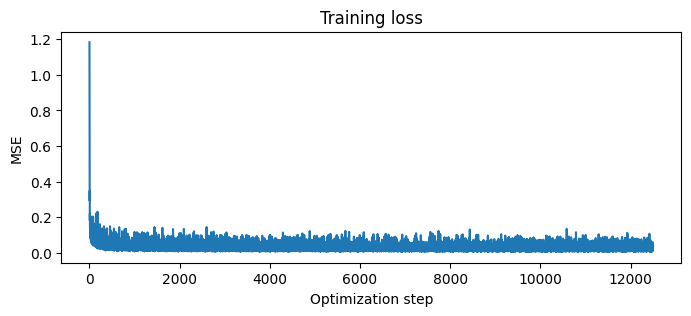

In [16]:
NUM_EPOCHS = 100
LEARNING_RATE = 4e-4

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
losses = []
model.train()

for epoch in range(NUM_EPOCHS):
    epoch_losses = []
    for clean_images in train_dataloader:
        clean_images = clean_images.to(device)
        noise = torch.randn_like(clean_images)
        timesteps = torch.randint(
            0,
            noise_scheduler.config.num_train_timesteps,
            (clean_images.shape[0],),
            device=device,
            dtype=torch.long,
        )
        noisy_images = noise_scheduler.add_noise(clean_images, noise, timesteps)
        noise_prediction = model(noisy_images, timesteps).sample
        loss = F.mse_loss(noise_prediction, noise)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        loss_value = loss.detach().cpu().item()
        losses.append(loss_value)
        epoch_losses.append(loss_value)

    mean_loss = sum(epoch_losses) / len(epoch_losses)
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS} - mean loss: {mean_loss:.4f}")

plt.figure(figsize=(8, 3))
plt.plot(losses)
plt.title("Training loss")
plt.xlabel("Optimization step")
plt.ylabel("MSE")
plt.show()

## Step 8: Generate images with the locally trained model

The pipeline combines the local U-Net and scheduler. Fifty inference steps keep this demonstration reasonably quick.

  0%|          | 0/50 [00:00<?, ?it/s]

Saved image grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/10-introduction-to-diffusion-models/generated_images/butterfly_grid_20261116_135409_962642.png


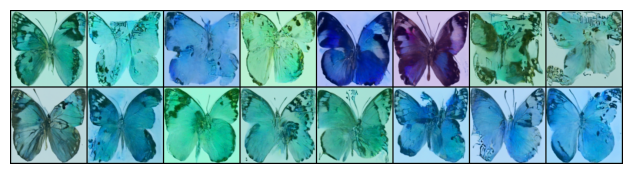

In [17]:
model.eval()
image_pipe = DDPMPipeline(unet=model, scheduler=noise_scheduler).to(device)

with torch.inference_mode():
    generated_images = image_pipe(
        batch_size=16,
        num_inference_steps=50,
    ).images

OUTPUT_DIR = Path("/Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/10-introduction-to-diffusion-models/generated_images")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

run_stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
image_grid = torchvision.utils.make_grid(
    torch.stack([transforms.ToTensor()(image) for image in generated_images]),
    nrow=8,
)

# Save only the grid with a unique timestamp so runs do not overwrite earlier outputs.
grid_path = OUTPUT_DIR / f"butterfly_grid_{run_stamp}.png"
torchvision.utils.save_image(image_grid, grid_path)
print(f"Saved image grid to: {grid_path.resolve()}")

plt.figure(figsize=(12, 2))
plt.imshow(image_grid.permute(1, 2, 0))
plt.axis("off")
plt.show()


## Step 9: Save locally (optional)

This writes the U-Net, scheduler, and pipeline metadata to `my_pipeline/`. It does not upload anything.

In [18]:
LOCAL_PIPELINE_DIR = "my_pipeline"
image_pipe.save_pretrained(LOCAL_PIPELINE_DIR)
print(f"Saved local pipeline to: {Path(LOCAL_PIPELINE_DIR).resolve()}")

Saved local pipeline to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/10-introduction-to-diffusion-models/my_pipeline
